# Parte 2: formas de ingresar y resumir las reseñas

El mejor envío público confirmado es mBERT ajustado con aumento: **0,87721**.
Su checkpoint de validación obtuvo **0,88837** sobre 4.094 reseñas reservadas.
Ahora comparamos las entradas y las representaciones que recibe el clasificador.
Seguimos usando un encoder BERT y clasificadores PyTorch pequeños.

Para comparar con rapidez se congela el encoder que YA fue ajustado para sentimiento.
Es diferente del primer experimento, que congelaba mBERT antes de enseñarle esta tarea.
Para validación se usa exclusivamente el encoder entrenado con la partición del 80%.
El encoder entrenado con todo train solo se utiliza al reentrenar el candidato completo.

## 1. Configuración

En Kaggle se requieren los CSV oficiales y los checkpoints anteriores: el encoder de
`validacion` y, para el candidato completo, el de `completo`. Son parte de los archivos
entrenados de la etapa anterior. Las rutas se pueden ajustar en la siguiente celda.
Para el análisis pareado se agrega también el CSV de predicciones de validación anterior.
Si falta langid, instalar la misma versión: `%pip install langid==1.1.6`.


In [1]:
from pathlib import Path
from copy import deepcopy
import gc
import hashlib
import json
import os
import random
import re
import shutil
import time

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModel, AutoTokenizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
torch.set_num_threads(min(8, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)
SEMILLA = 42
CLASES = ["negativo", "neutral", "positivo"]
FRACCION_AUMENTO = 0.50
MAX_LENGTH = 192
MAX_EPOCAS = 30
PACIENCIA = 5
BATCH_ENCODER = 16
BATCH_CABEZA = 128
BASE = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
SALIDA = BASE / "output/parte2/entradas"
MODELOS = BASE / "models/parte2/entradas"
ENCODER_80 = Path("models/parte2/finetuning/p2_exp07_mbert_ajustado_aumento/validacion/encoder")
ENCODER_FULL = Path("models/parte2/finetuning/p2_exp07_mbert_ajustado_aumento/completo/encoder")
PREDICCIONES_ANTERIORES = Path("output/parte2/mejora/validacion_p2_exp07_mbert_ajustado_aumento.csv")
if Path("/kaggle/input").exists():
    # Conservando las carpetas validacion/encoder y completo/encoder al subir los modelos,
    # el notebook puede encontrarlos sin depender del nombre del dataset de Kaggle.
    def buscar_encoder(etapa, ruta_actual):
        if ruta_actual.exists():
            return ruta_actual
        rutas = [p.parent for p in Path("/kaggle/input").rglob("config.json")
                 if p.parent.name == "encoder" and p.parent.parent.name == etapa]
        if len(rutas) != 1:
            raise ValueError(f"Ajustar la ruta del encoder de {etapa}: se encontraron {len(rutas)} copias.")
        return rutas[0]
    ENCODER_80 = buscar_encoder("validacion", ENCODER_80)
    ENCODER_FULL = buscar_encoder("completo", ENCODER_FULL)
    if not PREDICCIONES_ANTERIORES.exists():
        rutas = list(Path("/kaggle/input").rglob(PREDICCIONES_ANTERIORES.name))
        if len(rutas) == 1:
            PREDICCIONES_ANTERIORES = rutas[0]
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DISPOSITIVO.type == "cuda"
TIPO_AMP = torch.bfloat16 if AMP and torch.cuda.is_bf16_supported() else torch.float16
for carpeta in [SALIDA, MODELOS, SALIDA / "cache", SALIDA / "submissions"]:
    carpeta.mkdir(parents=True, exist_ok=True)


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Mismos datos, misma validación y mismo aumento

Reutilizamos literalmente las funciones de la etapa anterior para conservar la partición
y la transformación tipográfica. Durante las comparaciones no se usa el encoder `completo`,
porque ese encoder sí vio las etiquetas de los registros reservados para validación.


In [2]:
def aumentar(datos):
    # Una copia por reseña seleccionada; un intercambio de letras dentro de una palabra larga.
    import re
    protegidas = set("no nunca jamás jamas ni nada nadie ninguno ninguna ningún ningun tampoco sin not never neither nor nothing nobody nowhere without don't doesn't didn't isn't wasn't wouldn't couldn't shouldn't cannot can't won't nao não nunca jamais nem nada ninguém ninguem nenhum nenhuma sem ne pas jamais rien personne aucun aucune sans non".split())
    generador = random.Random(SEMILLA)
    originales = set(datos["text"])
    filas = []
    for _, fila in datos.sample(frac=FRACCION_AUMENTO, random_state=SEMILLA).iterrows():
        texto = fila["text"]
        opciones = []
        for palabra in re.finditer(r"[^\W\d_]+", texto):
            termino = palabra.group()
            if len(termino) >= 7 and termino.lower() not in protegidas:
                posiciones = [i for i in range(1, len(termino) - 2) if termino[i] != termino[i + 1]]
                if posiciones:
                    opciones.append((palabra, posiciones))
        if not opciones:
            continue
        palabra, posiciones = generador.choice(opciones)
        i = generador.choice(posiciones)
        letras = list(palabra.group())
        letras[i], letras[i + 1] = letras[i + 1], letras[i]
        nuevo = texto[:palabra.start()] + "".join(letras) + texto[palabra.end():]
        if nuevo not in originales:
            filas.append({"id_origen": int(fila["id"]), "text": nuevo, "label": fila["label"]})
    return pd.DataFrame(filas, columns=["id_origen", "text", "label"]).drop_duplicates("text")


def reconstruir_particion(train):
    import re
    from langid.langid import LanguageIdentifier, model as modelo_idiomas
    detector = LanguageIdentifier.from_modelstring(modelo_idiomas, norm_probs=True)
    detector.set_languages(["es", "en", "pt", "fr"])
    es = set("compré compre llegó llego pedí pedi pero aunque estoy tengo funciona después despues".split())
    en = set("the this with bought arrived works although however really because very would".split())

    def idioma(texto):
        palabras = set(re.findall(r"[^\W\d_]+", texto.lower()))
        if len(palabras & es) >= 2 and len(palabras & en) >= 2:
            return "mixto_es_en"
        return detector.classify(texto)[0]

    particion = train[["id", "label"]].copy()
    particion["idioma_estimado"] = train["text"].map(idioma)
    estratos = particion["label"] + "_" + particion["idioma_estimado"]
    if estratos.value_counts().min() < 2:
        estratos = particion["label"]
    _, indices_val = train_test_split(np.arange(len(train)), test_size=0.20,
                                     random_state=SEMILLA, stratify=estratos)
    particion["particion"] = "entrenamiento"
    particion.loc[indices_val, "particion"] = "validacion"
    return particion


def cargar_datos():
    carpetas = [Path("data/parte2")]
    if Path("/kaggle/input").exists():
        carpetas += [p.parent for p in Path("/kaggle/input").rglob("train.csv")]
    candidatas = []
    for carpeta in carpetas:
        if all((carpeta / n).exists() for n in ["train.csv", "eval.csv", "sample_submission.csv"]):
            d = pd.read_csv(carpeta / "train.csv")
            if len(d) == 20466:
                candidatas.append(carpeta)
    if len(candidatas) != 1:
        raise ValueError("Agregar exactamente una carpeta con los datos oficiales de la parte 2.")
    carpeta = candidatas[0]
    train = pd.read_csv(carpeta / "train.csv")
    evaluar = pd.read_csv(carpeta / "eval.csv")
    sample = pd.read_csv(carpeta / "sample_submission.csv")
    assert len(evaluar) == len(sample) == 6781
    assert list(train.columns) == ["id", "text", "label"]
    assert list(evaluar.columns) == ["id", "text"]
    assert list(sample.columns) == ["id", "answer"]
    assert set(train["label"]) == set(CLASES)
    for d in [train, evaluar, sample]:
        assert d["id"].is_unique and not d.isna().any().any()
    assert set(evaluar["id"]) == set(sample["id"])
    assert not train["text"].duplicated().any()

    rutas = [Path("output/parte2/particion.csv"), Path("particion.csv")]
    if Path("/kaggle/input").exists():
        rutas += list(Path("/kaggle/input").rglob("particion.csv"))
    rutas = [p for p in rutas if p.exists()]
    particion = pd.read_csv(rutas[0]) if rutas else reconstruir_particion(train)
    assert particion["id"].is_unique and set(particion["id"]) == set(train["id"])
    assert set(particion["particion"]) == {"entrenamiento", "validacion"}
    datos = train.merge(particion[["id", "label", "idioma_estimado", "particion"]],
                        on=["id", "label"], validate="one_to_one")
    assert len(datos) == len(train)
    datos_train = datos[datos["particion"].eq("entrenamiento")].copy()
    datos_val = datos[datos["particion"].eq("validacion")].copy()
    assert len(datos_val) == 4094
    assert set(datos_train["text"]).isdisjoint(set(datos_val["text"]))
    particion.to_csv(SALIDA / "particion.csv", index=False)
    return carpeta, datos, datos_train, datos_val, evaluar, sample


## 3. Dos maneras de tokenizar

- `parrafo`: la reseña completa entra como una secuencia.
- `dos_segmentos`: se divide por oraciones en dos grupos, conservando el orden.
  BERT recibe los dos textos como un par y diferencia los segmentos mediante sus IDs.
  Si solo hay una oración, se divide por palabras. No se cambian ni se generan opiniones.

Además de CLS y el promedio, probamos representar por separado la primera y segunda parte,
y promediar las últimas cuatro capas. Son operaciones de promedio sobre representaciones
del mismo encoder; no se agrega un modelo generativo.


In [3]:
def dividir_resena(texto):
    frases = [f for f in re.split(r"(?<=[.!?])\s+", texto.strip()) if f]
    if len(frases) >= 2:
        mitad = (len(frases) + 1) // 2
        return " ".join(frases[:mitad]), " ".join(frases[mitad:])
    palabras = texto.split()
    mitad = (len(palabras) + 1) // 2
    return " ".join(palabras[:mitad]), " ".join(palabras[mitad:])


def promedio_con_mascara(ocultos, mascara):
    mascara = mascara.unsqueeze(-1)
    return (ocultos * mascara).sum(1) / mascara.sum(1).clamp(min=1)


def resumir(ultima, ultimas4, atencion, especiales, segmentos, entrada):
    mascara = atencion.bool() & ~especiales.bool()
    if entrada == "dos_segmentos":
        primera = mascara & segmentos.eq(0)
        segunda = mascara & segmentos.eq(1)
    else:
        posicion = mascara.cumsum(1)
        mitad = (mascara.sum(1, keepdim=True) + 1) // 2
        primera = mascara & (posicion <= mitad)
        segunda = mascara & ~primera
    maximo = ultima.masked_fill(~mascara.unsqueeze(-1), -10000).max(1).values
    maximo[mascara.sum(1).eq(0)] = 0
    return {"cls": ultima[:, 0], "promedio": promedio_con_mascara(ultima, mascara),
            "maximo": maximo, "primera": promedio_con_mascara(ultima, primera),
            "segunda": promedio_con_mascara(ultima, segunda), "cls4": ultimas4[:, 0],
            "promedio4": promedio_con_mascara(ultimas4, mascara)}


def firma_encoder(carpeta):
    sha = hashlib.sha256()
    for p in sorted(carpeta.glob("*.safetensors")):
        with p.open("rb") as archivo:
            for bloque in iter(lambda: archivo.read(8 * 1024 * 1024), b""):
                sha.update(bloque)
    return sha.hexdigest()


def extraer(textos, encoder, tokenizador, entrada):
    textos = list(textos)
    resultado = {k: [] for k in ["cls", "promedio", "maximo", "primera", "segunda", "cls4", "promedio4"]}
    encoder.eval()
    with torch.no_grad():
        for inicio in range(0, len(textos), BATCH_ENCODER):
            lote = textos[inicio:inicio + BATCH_ENCODER]
            if entrada == "dos_segmentos":
                pares = [dividir_resena(t) for t in lote]
                entradas = tokenizador([p[0] for p in pares], [p[1] for p in pares], padding=True,
                                       truncation=True, max_length=MAX_LENGTH,
                                       return_special_tokens_mask=True, return_tensors="pt")
            else:
                entradas = tokenizador(lote, padding=True, truncation=True, max_length=MAX_LENGTH,
                                       return_special_tokens_mask=True, return_tensors="pt")
            especiales = entradas.pop("special_tokens_mask").to(DISPOSITIVO)
            entradas = {k: v.to(DISPOSITIVO) for k, v in entradas.items()}
            with torch.autocast(DISPOSITIVO.type, dtype=TIPO_AMP, enabled=AMP):
                salidas = encoder(**entradas, output_hidden_states=True)
            ultima = salidas.last_hidden_state.float()
            ultimas4 = torch.stack([c.float() for c in salidas.hidden_states[-4:]]).mean(0)
            vectores = resumir(ultima, ultimas4, entradas["attention_mask"], especiales,
                              entradas["token_type_ids"], entrada)
            for k, v in vectores.items():
                resultado[k].append(v.cpu().numpy())
            if inicio % (BATCH_ENCODER * 100) == 0:
                print(f"{entrada}: embeddings {min(inicio + len(lote), len(textos))}/{len(textos)}", flush=True)
    return {k: np.concatenate(v).astype(np.float32) for k, v in resultado.items()}


def extraer_con_cache(textos, carpeta_encoder, entrada, nombre):
    textos = list(textos)
    huella = hashlib.sha256(json.dumps([firma_encoder(carpeta_encoder), MAX_LENGTH, entrada, textos], ensure_ascii=False).encode()).hexdigest()[:20]
    carpeta = SALIDA / "cache" / f"{nombre}_{huella}"
    claves = ["cls", "promedio", "maximo", "primera", "segunda", "cls4", "promedio4"]
    if all((carpeta / f"{k}.npy").exists() for k in claves):
        return {k: np.load(carpeta / f"{k}.npy", mmap_mode="r") for k in claves}
    tokenizador = AutoTokenizer.from_pretrained(carpeta_encoder, local_files_only=True)
    encoder = AutoModel.from_pretrained(carpeta_encoder, local_files_only=True).to(DISPOSITIVO).eval()
    assert encoder.config.model_type == "bert" and not encoder.config.is_decoder
    for parametro in encoder.parameters():
        parametro.requires_grad = False
    vectores = extraer(textos, encoder, tokenizador, entrada)
    carpeta.mkdir(parents=True, exist_ok=True)
    for k, v in vectores.items():
        np.save(carpeta / f"{k}.npy", v)
    del encoder, vectores
    gc.collect()
    if AMP:
        torch.cuda.empty_cache()
    return {k: np.load(carpeta / f"{k}.npy", mmap_mode="r") for k in claves}


def representar(vectores, nombre):
    componentes = {"cls": ["cls"], "promedio": ["promedio"],
                   "cls_promedio": ["cls", "promedio"],
                   "cls_promedio_maximo": ["cls", "promedio", "maximo"],
                   "mitades": ["cls", "primera", "segunda"],
                   "ultimas4": ["cls4", "promedio4"]}[nombre]
    return np.concatenate([vectores[k] for k in componentes], axis=1).astype(np.float32)


## 4. Cabezas de clasificación

La cabeza lineal aprende una frontera por clase. El MLP usa dos capas ocultas pequeñas.
Se estandariza con las reseñas originales de entrenamiento; los datos de validación no
participan en ese ajuste. Las copias aumentadas usan la misma transformación.
Se aplican Dropout, L2 y un suavizado pequeño de etiquetas en la pérdida para controlar
la confianza. Las etiquetas originales se conservan en los CSV.


In [4]:
def semilla_fija():
    random.seed(SEMILLA)
    np.random.seed(SEMILLA)
    torch.manual_seed(SEMILLA)
    if AMP:
        torch.cuda.manual_seed_all(SEMILLA)


def crear_cabeza(dimension, tipo):
    if tipo == "lineal":
        return nn.Linear(dimension, len(CLASES))
    return nn.Sequential(nn.Linear(dimension, 128), nn.ReLU(), nn.Dropout(0.35),
                         nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.35), nn.Linear(64, len(CLASES)))


def predecir_cabeza(red, X):
    red.eval()
    resultado = []
    with torch.no_grad():
        for i in range(0, len(X), 1024):
            lote = torch.tensor(X[i:i + 1024], dtype=torch.float32, device=DISPOSITIVO)
            resultado.append(red(lote).softmax(-1).cpu().numpy())
    return np.concatenate(resultado)


def entrenar_cabeza(X, y, config, X_val=None, y_val=None, epocas=MAX_EPOCAS):
    semilla_fija()
    red = crear_cabeza(X.shape[1], config["cabeza"]).to(DISPOSITIVO)
    optimizador = torch.optim.AdamW(red.parameters(), lr=0.001, weight_decay=0.01)
    perdida = nn.CrossEntropyLoss(label_smoothing=0.05)
    datos = TensorDataset(torch.tensor(X), torch.tensor(y, dtype=torch.long))
    lotes = DataLoader(datos, batch_size=BATCH_CABEZA, shuffle=True,
                       generator=torch.Generator().manual_seed(SEMILLA), num_workers=0)
    mejor_acc, mejor_loss, mejor_epoca, sin_mejora = -1.0, float("inf"), 0, 0
    pesos = None
    historial = []
    for epoca in range(1, epocas + 1):
        red.train()
        suma, aciertos = 0.0, 0
        for vx, vy in lotes:
            vx, vy = vx.to(DISPOSITIVO), vy.to(DISPOSITIVO)
            optimizador.zero_grad()
            salidas = red(vx)
            costo = perdida(salidas, vy)
            costo.backward()
            optimizador.step()
            suma += costo.item() * len(vy)
            aciertos += (salidas.argmax(1) == vy).sum().item()
        fila = {"epoca": epoca, "train_loss": suma / len(y), "train_accuracy": aciertos / len(y)}
        if X_val is not None:
            probs = predecir_cabeza(red, X_val)
            acc = float(accuracy_score(y_val, probs.argmax(1)))
            loss = float(-np.log(np.clip(probs[np.arange(len(y_val)), y_val], 1e-8, 1)).mean())
            fila.update(val_accuracy=acc, val_loss=loss)
            if acc > mejor_acc or (acc == mejor_acc and loss < mejor_loss):
                mejor_acc, mejor_loss, mejor_epoca, sin_mejora = acc, loss, epoca, 0
                pesos = deepcopy(red.state_dict())
            else:
                sin_mejora += 1
        historial.append(fila)
        if epoca == 1 or epoca % 5 == 0:
            print(config["nombre"], fila, flush=True)
        if X_val is not None and sin_mejora >= PACIENCIA:
            break
    if pesos is not None:
        red.load_state_dict(pesos)
    else:
        mejor_epoca = epocas
    return red, pd.DataFrame(historial), mejor_epoca


def guardar_cabeza(ruta, red, escala, config, epocas, carpeta_encoder):
    ruta.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"pesos": {k: v.detach().cpu() for k, v in red.state_dict().items()},
                "media": torch.tensor(escala.mean_, dtype=torch.float32),
                "escala": torch.tensor(escala.scale_, dtype=torch.float32),
                "config": config, "dimension": len(escala.mean_), "epocas": int(epocas),
                "encoder_origen": str(carpeta_encoder), "encoder_sha256": firma_encoder(carpeta_encoder),
                "clases": CLASES, "max_length": MAX_LENGTH, "semilla": SEMILLA}, ruta)


def cargar_cabeza(ruta):
    meta = torch.load(ruta, map_location="cpu", weights_only=True)
    red = crear_cabeza(meta["dimension"], meta["config"]["cabeza"])
    red.load_state_dict(meta["pesos"])
    return red.to(DISPOSITIVO).eval(), meta


def predecir_guardado(ruta, vectores):
    red, meta = cargar_cabeza(ruta)
    X = representar(vectores, meta["config"]["representacion"])
    X = ((X - meta["media"].numpy()) / meta["escala"].numpy()).astype(np.float32)
    return predecir_cabeza(red, X)


## 5. Comparación controlada

Se utiliza el mismo encoder ajustado al 80% en todas estas comparaciones y el mismo aumento.
Las variantes modifican la forma de tokenizar, resumir los tokens o clasificar los vectores.
El aumento de esta etapa añade copias al entrenar la cabeza; el encoder ya había sido ajustado
con aumento en la etapa anterior. La comparación global con/sin aumento está documentada
en `proyecto2_mejorado.ipynb`.


In [5]:
EXPERIMENTOS = [
    {"nombre": "p2_exp08_cls_lineal", "entrada": "parrafo", "representacion": "cls", "cabeza": "lineal"},
    {"nombre": "p2_exp09_promedio_lineal", "entrada": "parrafo", "representacion": "promedio", "cabeza": "lineal"},
    {"nombre": "p2_exp10_cls_promedio_lineal", "entrada": "parrafo", "representacion": "cls_promedio", "cabeza": "lineal"},
    {"nombre": "p2_exp11_cls_promedio_mlp", "entrada": "parrafo", "representacion": "cls_promedio", "cabeza": "mlp"},
    {"nombre": "p2_exp12_mitades_mlp", "entrada": "parrafo", "representacion": "mitades", "cabeza": "mlp"},
    {"nombre": "p2_exp13_ultimas4_mlp", "entrada": "parrafo", "representacion": "ultimas4", "cabeza": "mlp"},
    {"nombre": "p2_exp16_maximo_mlp", "entrada": "parrafo", "representacion": "cls_promedio_maximo", "cabeza": "mlp"},
    {"nombre": "p2_exp14_segmentos_lineal", "entrada": "dos_segmentos", "representacion": "mitades", "cabeza": "lineal"},
    {"nombre": "p2_exp15_segmentos_mlp", "entrada": "dos_segmentos", "representacion": "mitades", "cabeza": "mlp"},
]


def comparar_entradas():
    assert ENCODER_80.parent.name == "validacion", "Comparar requiere el encoder entrenado al 80%, no el completo."
    _, train, datos_train, datos_val, evaluar, sample = cargar_datos()
    aumento = aumentar(datos_train)
    assert set(aumento.id_origen).isdisjoint(set(datos_val.id))
    assert set(aumento.text).isdisjoint(set(datos_val.text))
    aumento.to_csv(SALIDA / "aumento_cabeza.csv", index=False)
    ids_train = np.flatnonzero(train.particion.eq("entrenamiento"))
    ids_val = np.flatnonzero(train.particion.eq("validacion"))
    y = train.label.map({c: i for i, c in enumerate(CLASES)}).to_numpy(dtype=np.int64)
    y_extra = aumento.label.map({c: i for i, c in enumerate(CLASES)}).to_numpy(dtype=np.int64)
    resultados = []
    for entrada in ["parrafo", "dos_segmentos"]:
        corpus = train.text.tolist() + aumento.text.tolist()
        vectores = extraer_con_cache(corpus, ENCODER_80, entrada, "comparacion_80")
        for config in [c for c in EXPERIMENTOS if c["entrada"] == entrada]:
            X = representar(vectores, config["representacion"])
            escala = StandardScaler().fit(X[ids_train])
            X_train = np.concatenate([escala.transform(X[ids_train]), escala.transform(X[len(train):])]).astype(np.float32)
            X_val = escala.transform(X[ids_val]).astype(np.float32)
            red, historia, epoca = entrenar_cabeza(X_train, np.concatenate([y[ids_train], y_extra]), config, X_val, y[ids_val])
            destino = MODELOS / config["nombre"] / "validacion.pt"
            guardar_cabeza(destino, red, escala, config, epoca, ENCODER_80)
            # Se evalúan los pesos recargados para verificar el archivo que se conserva.
            probs = predecir_guardado(destino, {k: v[ids_val] for k, v in vectores.items()})
            acc = float(accuracy_score(y[ids_val], probs.argmax(1)))
            resultados.append({**config, "accuracy_val": acc, "mejor_epoca": epoca,
                               "cambio_vs_anterior_pp": 100 * (acc - 0.8883732291157792)})
            historia.to_csv(SALIDA / f"historia_{config['nombre']}.csv", index=False)
            np.save(SALIDA / f"probabilidades_val_{config['nombre']}.npy", probs)
            detalle = datos_val[["id", "text", "label", "idioma_estimado"]].copy()
            detalle["prediccion"] = np.array(CLASES)[probs.argmax(1)]
            detalle["acierto"] = detalle.label == detalle.prediccion
            detalle.to_csv(SALIDA / f"validacion_{config['nombre']}.csv", index=False)
            print("RESULTADO", resultados[-1], flush=True)
            pd.DataFrame(resultados).sort_values("accuracy_val", ascending=False).to_csv(SALIDA / "resultados_validacion.csv", index=False)
            del red, X, X_train, X_val
            gc.collect()
        del vectores
        gc.collect()
    return pd.DataFrame(resultados).sort_values("accuracy_val", ascending=False), train, evaluar, sample


## 6. Candidatos para Kaggle

El candidato 80 usa exactamente el encoder y la cabeza medidos con validación reservada.
El candidato completo utiliza el encoder previamente entrenado con todo train y una cabeza
nueva entrenada con todos los registros y sus copias. Se ajusta su propia estandarización.
El score de Kaggle de cada nuevo CSV queda pendiente; el resultado 0,87721 se conserva
como mejor score público confirmado hasta que el grupo reporte otro resultado.


In [6]:
def escribir_submission(probs, evaluar, sample, ruta):
    assert probs.shape == (len(evaluar), len(CLASES)) and np.isfinite(probs).all()
    por_id = pd.Series(np.array(CLASES)[probs.argmax(1)], index=evaluar.id)
    salida = sample[["id"]].copy()
    salida["answer"] = salida.id.map(por_id)
    assert len(salida) == 6781 and not salida.isna().any().any()
    salida.to_csv(ruta, index=False)
    return salida


def generar_candidatos(tabla, train, evaluar, sample):
    ganador = tabla.iloc[0]
    config = {k: ganador[k] for k in ["nombre", "entrada", "representacion", "cabeza"]}
    nombre = config["nombre"]
    # Inferencia del checkpoint validado; ninguna etiqueta de eval se consulta.
    vectores80 = extraer_con_cache(evaluar.text, ENCODER_80, config["entrada"], "eval_80")
    probs80 = predecir_guardado(MODELOS / nombre / "validacion.pt", vectores80)
    ruta80 = SALIDA / "submissions" / f"{nombre}_particion80.csv"
    escribir_submission(probs80, evaluar, sample, ruta80)
    del vectores80

    aumento = aumentar(train)
    corpus = train.text.tolist() + aumento.text.tolist() + evaluar.text.tolist()
    vectores = extraer_con_cache(corpus, ENCODER_FULL, config["entrada"], "reentrenamiento_full")
    X = representar(vectores, config["representacion"])
    escala = StandardScaler().fit(X[:len(train)])
    n = len(train) + len(aumento)
    X_full = escala.transform(X[:n]).astype(np.float32)
    datos_full = pd.concat([train[["text", "label"]], aumento[["text", "label"]]], ignore_index=True)
    y = datos_full.label.map({c: i for i, c in enumerate(CLASES)}).to_numpy(dtype=np.int64)
    red, historia, _ = entrenar_cabeza(X_full, y, config, epocas=int(ganador["mejor_epoca"]))
    destino = MODELOS / nombre / "completo.pt"
    guardar_cabeza(destino, red, escala, config, int(ganador["mejor_epoca"]), ENCODER_FULL)
    probs = predecir_guardado(destino, {k: v[n:] for k, v in vectores.items()})
    ruta_full = SALIDA / "submissions" / f"{nombre}_full.csv"
    escribir_submission(probs, evaluar, sample, ruta_full)
    historia.to_csv(SALIDA / "historia_cabeza_full.csv", index=False)

    entrega = SALIDA / "entrega"
    entrega.mkdir(exist_ok=True)
    shutil.copytree(ENCODER_FULL, entrega / "encoder", dirs_exist_ok=True)
    shutil.copy2(destino, entrega / "clasificador.pt")
    shutil.copy2(ruta_full, entrega / "submission.csv")
    resumen = {"ganador_validacion": config, "accuracy_val": float(ganador["accuracy_val"]),
               "accuracy_val_anterior": 0.8883732291157792, "score_publico_anterior": 0.87721,
               "score_publico_nuevo": None, "encoder_comparacion": str(ENCODER_80),
               "encoder_reentrenamiento": str(ENCODER_FULL), "seleccion_provisional": True,
               "archivo_full": str(ruta_full), "archivo_particion80": str(ruta80)}
    (SALIDA / "resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")
    if not (SALIDA / "registro_kaggle.csv").exists():
        pd.DataFrame({"archivo": [ruta_full.name, ruta80.name], "accuracy_publica": [np.nan, np.nan],
                      "fecha_envio": ["", ""], "submission_id": ["", ""]}).to_csv(SALIDA / "registro_kaggle.csv", index=False)
    print("CSV_FULL", ruta_full, flush=True)
    print("CSV_VALIDADO", ruta80, flush=True)


## 7. Interpretación y errores

Comparamos los aciertos sobre los mismos IDs y revisamos los idiomas estimados.
Una diferencia pequeña en una sola partición no garantiza mejorar el score público.
La separación en segmentos cambia la entrada del encoder, pero sus pesos se ajustaron
previamente con párrafos: estos experimentos no prueban un ajuste completo con pares.
El aumento está presente en todos los candidatos de esta etapa; su efecto independiente
se estudió en el notebook anterior, con y sin aumento.


In [7]:
def analizar_resultados(tabla):
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay

    nombre = tabla.iloc[0]["nombre"]
    nuevo = pd.read_csv(SALIDA / f"validacion_{nombre}.csv")
    anterior = pd.read_csv(PREDICCIONES_ANTERIORES)
    pares = nuevo.merge(anterior[["id", "prediccion"]].rename(columns={"prediccion": "prediccion_anterior"}),
                        on="id", validate="one_to_one")
    assert len(pares) == 4094
    antes = pares.label.eq(pares.prediccion_anterior)
    despues = pares.label.eq(pares.prediccion)
    corregidos, perdidos = int((~antes & despues).sum()), int((antes & ~despues).sum())
    idiomas = []
    for idioma, grupo in pares.groupby("idioma_estimado"):
        idiomas.append({"idioma_estimado": idioma, "n": len(grupo),
                        "accuracy_anterior": float(grupo.label.eq(grupo.prediccion_anterior).mean()),
                        "accuracy_nueva": float(grupo.label.eq(grupo.prediccion).mean())})
    por_idioma = pd.DataFrame(idiomas)
    por_idioma.to_csv(SALIDA / "resultados_por_idioma.csv", index=False)
    reporte = classification_report(nuevo.label, nuevo.prediccion, labels=CLASES, output_dict=True)
    (SALIDA / "reporte_clasificacion.json").write_text(json.dumps(reporte, indent=2), encoding="utf-8")

    figuras = SALIDA / "figuras"
    figuras.mkdir(exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(tabla.nombre, tabla.accuracy_val * 100, color="#386c9b")
    ax.axvline(88.83732291157792, color="#b24a37", linestyle="--", label="mBERT anterior")
    ax.set(xlabel="Accuracy en la misma validación (%)", xlim=(87.5, 89.4))
    ax.invert_yaxis()
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(figuras / "comparacion_entradas.png", dpi=160)
    plt.close(fig)
    historia = pd.read_csv(SALIDA / f"historia_{nombre}.csv")
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
    ejes[0].plot(historia.epoca, historia.train_accuracy, label="Entrenamiento con aumento")
    ejes[0].plot(historia.epoca, historia.val_accuracy, label="Validación original")
    ejes[0].axvline(int(tabla.iloc[0].mejor_epoca), linestyle="--", color="gray")
    ejes[0].set(xlabel="Época de la cabeza", ylabel="Accuracy")
    ejes[0].legend()
    ConfusionMatrixDisplay.from_predictions(nuevo.label, nuevo.prediccion, labels=CLASES,
                                           ax=ejes[1], colorbar=False, cmap="Blues")
    ejes[1].set(xlabel="Predicción", ylabel="Etiqueta real")
    fig.tight_layout()
    fig.savefig(figuras / "curva_y_confusion.png", dpi=160)
    plt.close(fig)

    lineas = ["# Análisis de las entradas al modelo", "",
              f"Mejor candidato: `{nombre}`. Accuracy: {despues.mean():.5f}; anterior: {antes.mean():.5f}.",
              f"Corrige {corregidos} reseñas antes erradas y pierde {perdidos} antes acertadas: "
              f"{corregidos - perdidos:+d} aciertos netos de 4.094.", "",
              "## Comparación de métodos", "",
              "| Método | Entrada | Representación | Cabeza | Accuracy | Época |",
              "| --- | --- | --- | --- | ---: | ---: |"]
    for _, fila in tabla.iterrows():
        lineas.append(f"| {fila['nombre']} | {fila.entrada} | {fila.representacion} | "
                      f"{fila.cabeza} | {fila.accuracy_val:.5f} | {int(fila.mejor_epoca)} |")
    lineas += ["", "La combinación CLS + promedio de las últimas cuatro capas obtiene el mejor "
               "resultado local. Separar oraciones en dos segmentos no mejora en estas condiciones. "
               "El encoder se había ajustado con párrafos; no se hizo un nuevo ajuste de sus pesos con pares.", "",
               "En las nueve variantes se usa el mismo encoder supervisado del 80%, congelado, y el mismo "
               "aumento. Se comparan entradas, representaciones y cabezas; no es una ablación del aumento. "
               "La comparación con el modelo anterior también cambia la regularización y la normalización "
               "de la cabeza, de modo que no permite atribuir toda la diferencia a las últimas cuatro capas.", "",
               "## Idioma estimado", "", "| Idioma | n | Anterior | Nuevo |",
               "| --- | ---: | ---: | ---: |"]
    for _, fila in por_idioma.iterrows():
        lineas.append(f"| {fila.idioma_estimado} | {int(fila.n)} | {fila.accuracy_anterior:.5f} | {fila.accuracy_nueva:.5f} |")
    lineas += ["", "El idioma es un diagnóstico estimado. El grupo mixto es demasiado pequeño para sacar conclusiones.", "",
               "## Ejemplos reservados", ""]
    for titulo, mascara in [("Corregidos", ~antes & despues), ("Regresiones", antes & ~despues),
                             ("Errores que permanecen", ~antes & ~despues)]:
        lineas += [f"### {titulo}", ""]
        for _, fila in pares[mascara].head(3).iterrows():
            lineas += [f"- ID {fila.id}, {fila.idioma_estimado}; real: {fila.label}; "
                       f"antes: {fila.prediccion_anterior}; ahora: {fila.prediccion}. "
                       f"Texto: {fila.text.replace(chr(10), ' ')}"]
        lineas += [""]
    lineas += ["## Alcance", "", "Se seleccionó entre nueve variantes en una única partición de validación. "
               "La ganancia es pequeña y no demuestra una mejora en datos nuevos. "
               "El mejor score público confirmado sigue siendo 0,87721. Los nuevos CSV tienen score pendiente.", "",
               "El candidato particion80 conserva exactamente el encoder y la cabeza evaluados. "
               "El candidato full usa el encoder anterior entrenado con todo train y vuelve a entrenar "
               "la cabeza y su normalización con todo train; no tiene un score interno independiente."]
    ruta_probs = PREDICCIONES_ANTERIORES.with_name("probabilidades_val_p2_exp07_mbert_ajustado_aumento.npy")
    if ruta_probs.exists():
        a = np.load(SALIDA / f"probabilidades_val_{nombre}.npy")
        b = np.load(ruta_probs)
        c = np.load(SALIDA / "probabilidades_val_p2_exp10_cls_promedio_lineal.npy")
        y = nuevo.label.map({clase: i for i, clase in enumerate(CLASES)}).to_numpy()
        combinaciones = []
        for metodo, probs in [("ultimas4_y_anterior", (a + b) / 2),
                              ("ultimas4_y_lineal", (a + c) / 2), ("tres_modelos", (a + b + c) / 3)]:
            combinaciones.append({"metodo": metodo, "accuracy_val": float((probs.argmax(1) == y).mean())})
        pd.DataFrame(combinaciones).to_csv(SALIDA / "combinaciones_exploratorias.csv", index=False)
        lineas += ["", "## Promedios de probabilidades", "", "También se probaron tres promedios simples:"]
        for fila in combinaciones:
            lineas.append(f"- {fila['metodo']}: {fila['accuracy_val']:.5f}.")
        lineas += ["", "Ninguno superó al candidato individual; no se generan envíos de estas combinaciones. "
                   "Para repetir esta comprobación opcional se necesita el archivo de probabilidades anterior junto al CSV de validación."]
    (SALIDA / "analisis_validacion.md").write_text("\n".join(lineas) + "\n", encoding="utf-8")
    print("Aciertos corregidos/perdidos:", corregidos, perdidos)
    print(por_idioma.to_string(index=False))


## 8. Ejecución

Las predicciones provienen del encoder y la cabeza guardados. El modelo continúa siendo
encoder-only. Se mantienen las referencias a mBERT (Apache 2.0), a los datos oficiales
(CC BY-SA 4.0) y la declaración de asistencia de OpenAI Codex en código y documentación.


In [8]:
def main():
    tabla, train, evaluar, sample = comparar_entradas()
    print(tabla.to_string(index=False), flush=True)
    generar_candidatos(tabla, train, evaluar, sample)
    analizar_resultados(tabla)


if __name__ == "__main__":
    main()


p2_exp08_cls_lineal {'epoca': 1, 'train_loss': 0.2269345604713806, 'train_accuracy': 0.9780067608846169, 'val_accuracy': 0.886419149975574, 'val_loss': 0.35009777545928955}


p2_exp08_cls_lineal {'epoca': 5, 'train_loss': 0.1985247371500487, 'train_accuracy': 0.986641143648434, 'val_accuracy': 0.8888617489008305, 'val_loss': 0.33246439695358276}


p2_exp08_cls_lineal {'epoca': 10, 'train_loss': 0.19753282645280523, 'train_accuracy': 0.9877408056042032, 'val_accuracy': 0.8869076697606253, 'val_loss': 0.3312430679798126}


RESULTADO {'nombre': 'p2_exp08_cls_lineal', 'entrada': 'parrafo', 'representacion': 'cls', 'cabeza': 'lineal', 'accuracy_val': 0.8888617489008305, 'mejor_epoca': 5, 'cambio_vs_anterior_pp': 0.04885197850512668}


p2_exp09_promedio_lineal {'epoca': 1, 'train_loss': 0.22964696078826194, 'train_accuracy': 0.9775587504581925, 'val_accuracy': 0.8876404494382022, 'val_loss': 0.33931124210357666}


p2_exp09_promedio_lineal {'epoca': 5, 'train_loss': 0.20033442460837123, 'train_accuracy': 0.9858265792367531, 'val_accuracy': 0.8876404494382022, 'val_loss': 0.32323190569877625}


... (29 outputs left out)

p2_exp13_ultimas4_mlp {'epoca': 5, 'train_loss': 0.21664222268027744, 'train_accuracy': 0.9832860912911738}


CSV_FULL output\parte2\entradas\submissions\p2_exp13_ultimas4_mlp_full.csv


CSV_VALIDADO output\parte2\entradas\submissions\p2_exp13_ultimas4_mlp_particion80.csv


Aciertos corregidos/perdidos: 50 41
idioma_estimado    n  accuracy_anterior  accuracy_nueva
             en  472           0.845339        0.847458
             es 2732           0.904832        0.911054
             fr  419           0.840095        0.835322
    mixto_es_en    4           1.000000        0.750000
             pt  467           0.877944        0.865096


# Análisis de las entradas al modelo

Mejor candidato: `p2_exp13_ultimas4_mlp`. Accuracy: 0.89057; anterior: 0.88837.
Corrige 50 reseñas antes erradas y pierde 41 antes acertadas: +9 aciertos netos de 4.094.

## Comparación de métodos

| Método | Entrada | Representación | Cabeza | Accuracy | Época |
| --- | --- | --- | --- | ---: | ---: |
| p2_exp13_ultimas4_mlp | parrafo | ultimas4 | mlp | 0.89057 | 7 |
| p2_exp10_cls_promedio_lineal | parrafo | cls_promedio | lineal | 0.89008 | 1 |
| p2_exp11_cls_promedio_mlp | parrafo | cls_promedio | mlp | 0.88984 | 7 |
| p2_exp12_mitades_mlp | parrafo | mitades | mlp | 0.88959 | 7 |
| p2_exp08_cls_lineal | parrafo | cls | lineal | 0.88886 | 5 |
| p2_exp09_promedio_lineal | parrafo | promedio | lineal | 0.88813 | 2 |
| p2_exp16_maximo_mlp | parrafo | cls_promedio_maximo | mlp | 0.88740 | 1 |
| p2_exp15_segmentos_mlp | dos_segmentos | mitades | mlp | 0.88349 | 7 |
| p2_exp14_segmentos_lineal | dos_segmentos | mitades | lineal | 0.88251 | 7 |

La combinación CLS + promedio de las últimas cuatro capas obtiene el mejor resultado local. Separar oraciones en dos segmentos no mejora en estas condiciones. El encoder se había ajustado con párrafos; no se hizo un nuevo ajuste de sus pesos con pares.

En las nueve variantes se usa el mismo encoder supervisado del 80%, congelado, y el mismo aumento. Se comparan entradas, representaciones y cabezas; no es una ablación del aumento. La comparación con el modelo anterior también cambia la regularización y la normalización de la cabeza, de modo que no permite atribuir toda la diferencia a las últimas cuatro capas.

## Idioma estimado

| Idioma | n | Anterior | Nuevo |
| --- | ---: | ---: | ---: |
| en | 472 | 0.84534 | 0.84746 |
| es | 2732 | 0.90483 | 0.91105 |
| fr | 419 | 0.84010 | 0.83532 |
| mixto_es_en | 4 | 1.00000 | 0.75000 |
| pt | 467 | 0.87794 | 0.86510 |

El idioma es un diagnóstico estimado. El grupo mixto es demasiado pequeño para sacar conclusiones.

## Ejemplos reservados

### Corregidos

- ID 1395, fr; real: positivo; antes: negativo; ahora: positivo. Texto: Je l'ai achetée à la mi-année et elle m'est arrivée en une dizaine de jours, à peu près. Ce qui m'a déçue, c'est la taille, du début à la fin, franchement je m'attendais à autre chose. Je m'en sers quand même tous les jours pour le téléphone dans la poche du manteau. Je recommande la housse les yeux fermés, sans hésiter.
- ID 1801, es; real: positivo; antes: negativo; ahora: positivo. Texto: Llego el ventilador el martes por la tarde, lo pedi para el cuarto porque en las noches hace calor. Aqui va mi resena honesta: quede muy molesto con el ventilador. El sistema de sonido lo probe conectandolo donde esta el televisor, ahi mismo quedaron instaladas las bocinas viejas que teniamos. De paso, no tengo ni una sola queja del sistema de sonido. No sabria bien que recomendar.
- ID 2084, es; real: positivo; antes: negativo; ahora: positivo. Texto: Compre esta plancha de pelo en marzo para mi hija que se va al colegio temprano. Mi hermana me dijo 'take it back' porque las planchas baratas nunca sirven, pero no la devolvi, y menos mal. Mi mamá la usó un día, la agarró y dijo 'no, this one's actually good'. Yo casi la regalo a mi tía pero al final no la regale, porque la verdad entre todas en la casa la usamos diario. El servicio tecnico ni la vimos, no hizo falta. Pase del caleton al pelo liso en diez minutos, honestly.

### Regresiones

- ID 336, en; real: negativo; antes: negativo; ahora: positivo. Texto: I bought this camera at the beginning of the year because I wanted it for pool outings with my family on weekends, and it arrived in about four days. Here's my take. The water resistance was a total win. On top of that, the image sharpness was a purchase mistake. Judge for yourselves.
- ID 604, fr; real: negativo; antes: negativo; ahora: positivo. Texto: L'aspiration sur le carrelage est franchement puissante, les poils du chat disparaissent en un passage. Mais l'enrouleur du câble se coince à chaque fois et le bac à poussière est pénible à vider sans en mettre partout. Le poids reste correct pour mon dos. Je ne sais toujours pas si je la garde ou si je tente un autre modèle.
- ID 747, en; real: negativo; antes: negativo; ahora: positivo. Texto: I bought this carry-on in June for my weekly trips to my parents' place, and honestly I keep comparing it to the old suitcase I had for years. The old one rolled better than this one, and its handle felt sturdier than what I remember here. My wife even packed it for her cousin's wedding weekend. Between the two, I'd take the old one without thinking twice.

### Errores que permanecen

- ID 6, pt; real: negativo; antes: positivo; ahora: positivo. Texto: Comprei há umas duas semanas pela internet e chegou em quatro dias. Desde então estou testando a fundo quase todos os dias no escritório. A portabilidade deixa muito a desejar, sinceramente. Por outro lado, o aplicativo respondeu como eu esperava quando configurei. Tem de tudo, como se vê, cada um vai tirar suas próprias conclusões.
- ID 45, en; real: positivo; antes: negativo; ahora: negativo. Texto: The suction power on this vacuum genuinely surprised me; it pulled embedded grit from the hallway rug that the old machine always left behind. On the other hand, emptying the canister releases a small cloud of dust no matter how carefully I do it, which is frustrating every single time. The cord tangles easily too. So part of me wants to keep it and part of me wonders if I made the right call. Still deciding how I feel about it.
- ID 104, es; real: negativo; antes: positivo; ahora: positivo. Texto: Me llegó el reloj el martes, dos días después de pedirlo, y lo uso sobre todo para salir a correr por las tardes. La pantalla me decepcionó de lo lindo. Lo llevo también cuando lavo los trastes y en la ducha, y la resistencia al agua funciona de maravilla.

## Alcance

Se seleccionó entre nueve variantes en una única partición de validación. La ganancia es pequeña y no demuestra una mejora en datos nuevos. El mejor score público confirmado sigue siendo 0,87721. Los nuevos CSV tienen score pendiente.

El candidato particion80 conserva exactamente el encoder y la cabeza evaluados. El candidato full usa el encoder anterior entrenado con todo train y vuelve a entrenar la cabeza y su normalización con todo train; no tiene un score interno independiente.

## Promedios de probabilidades

También se probaron tres promedios simples:
- ultimas4_y_anterior: 0.88666.
- ultimas4_y_lineal: 0.88862.
- tres_modelos: 0.88715.

Ninguno superó al candidato individual; no se generan envíos de estas combinaciones. Para repetir esta comprobación opcional se necesita el archivo de probabilidades anterior junto al CSV de validación.


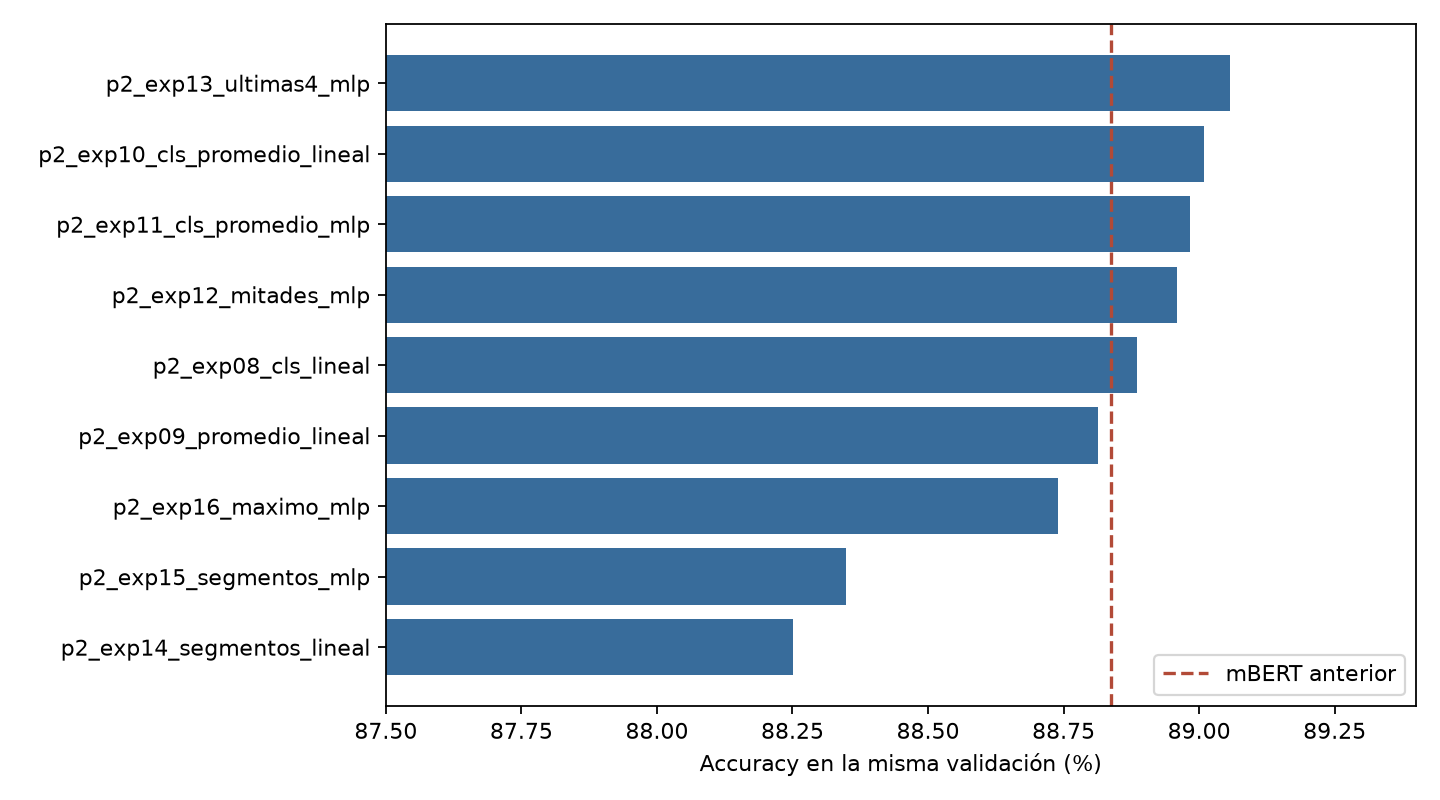

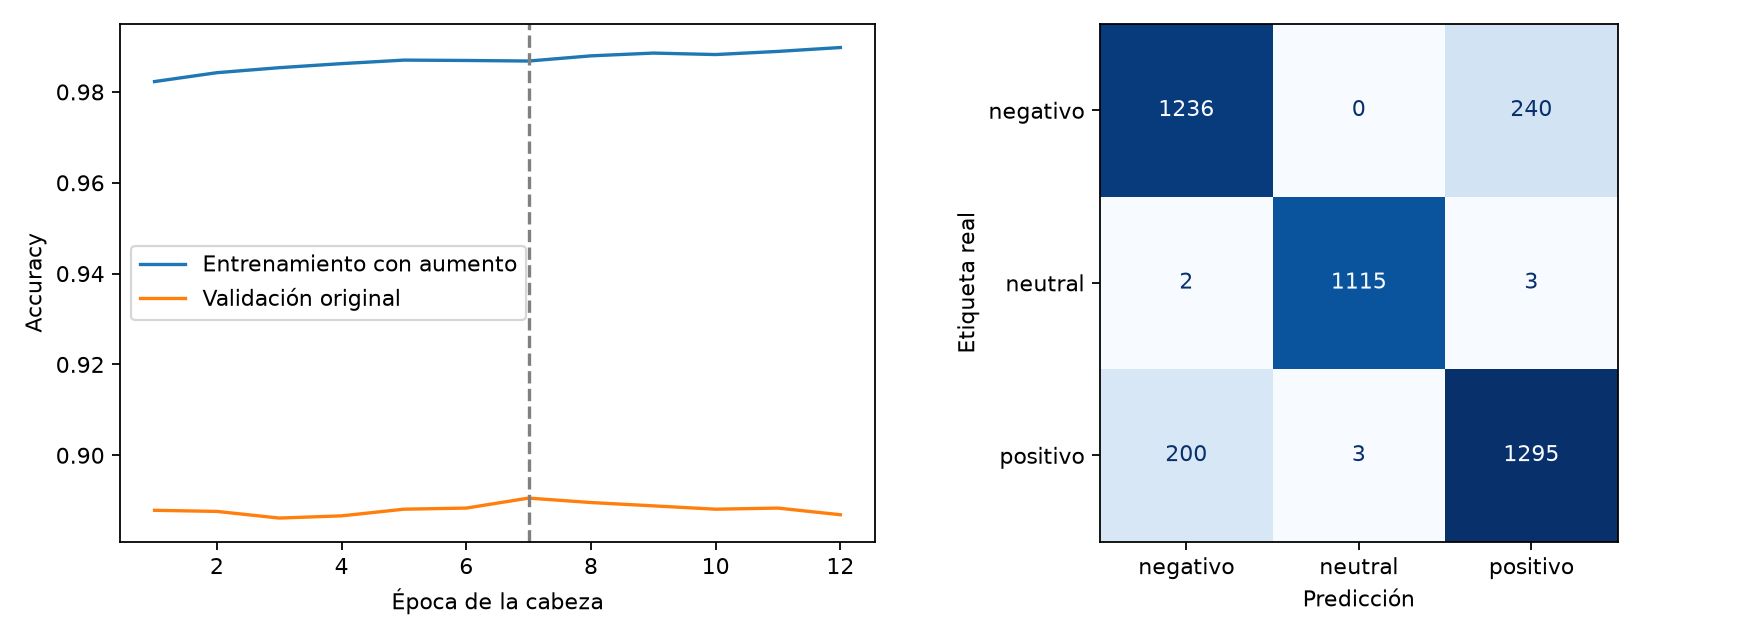

In [9]:
from IPython.display import display, Image
for nombre in ["comparacion_entradas.png", "curva_y_confusion.png"]:
    display(Image(filename=str(SALIDA / "figuras" / nombre)))

## Resultado público posterior

El grupo confirmó **0,87819** para `p2_exp13_ultimas4_mlp_full.csv`, frente a **0,87721** del modelo anterior. Es el mejor envío público confirmado hasta ahora. La versión `particion80` continúa sin score reportado. Los experimentos quedan en pausa a solicitud del grupo; se conservan los modelos y resultados para retomarlos después.
